In [ ]:
# ============================================================
# Cell 1 — Install & Imports
# ============================================================

!pip -q install "httpx[http2]==0.28.1" --upgrade
!pip -q install codecarbon psutil nvidia-ml-py3 pandas matplotlib --upgrade

import os, json, time, csv, threading, math, shutil, platform, uuid, glob
from dataclasses import dataclass, asdict
from datetime import datetime
from typing import Optional, Dict, Any, List
from pathlib import Path

import psutil
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# GPU NVML (safe import)
try:
    import pynvml
    pynvml.nvmlInit()
    NVML_AVAILABLE = True
    NVML_DEVICE_COUNT = pynvml.nvmlDeviceGetCount()
except Exception:
    NVML_AVAILABLE = False
    NVML_DEVICE_COUNT = 0

from codecarbon import EmissionsTracker

import torch
from torch import nn, optim
import torchvision
from torchvision import transforms

# Plot style
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True

SEED = 42
torch.manual_seed(SEED)

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("NVML available:", NVML_AVAILABLE, "| devices:", NVML_DEVICE_COUNT)


  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 357.4/357.4 kB 10.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 263.3/263.3 kB 24.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 109.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.7/8.7 MB 99.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 102.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.4/76.4 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 92.5/92.5 kB 8.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
firebase-admin 6.9.0 requires httpx[http2]==0.28.1, but you

In [ ]:
# ============================================================
# Cell 2 — Run Configuration
# ============================================================

PROJECT_NAME     = "carbon_calculator_mvp"
OUTPUT_ROOT      = "/content/carbon_logs"

# Toggle here:
USE_ONLINE        = False            # False = offline regional factors; True = online auto
COUNTRY_ISO_CODE  = "KOR"            # Used in offline mode: "CAN", "MEX", "KOR", "MNG"
PUE               = 1.20             # Data-center PUE
SAMPLE_SECONDS    = 1.0              # CPU/GPU sampling cadence (seconds)

RUN_NAME          = "mnist_demo"
PRICE_PER_KWH_USD = 0.18             # Optional cost
HOURLY_RATE_USD   = None             # Optional compute cost

os.makedirs(OUTPUT_ROOT, exist_ok=True)

# Create unique RUN_DIR for this training
ts = datetime.now().strftime("%Y%m%d-%H%M%S")
mode_tag = "online" if USE_ONLINE else COUNTRY_ISO_CODE
RUN_DIR = os.path.join(OUTPUT_ROOT, f"{ts}_{RUN_NAME}_{mode_tag}")
os.makedirs(RUN_DIR, exist_ok=True)

print("OUTPUT_ROOT:", OUTPUT_ROOT)
print("RUN_DIR:", RUN_DIR)
print("Mode:", "ONLINE" if USE_ONLINE else f"OFFLINE ({COUNTRY_ISO_CODE})")
print("PUE:", PUE)


OUTPUT_ROOT: /content/carbon_logs
RUN_DIR: /content/carbon_logs/20251129-083342_mnist_demo_KOR
Mode: OFFLINE (KOR)
PUE: 1.2


In [ ]:
# ============================================================
# Cell 3 — UsageSampler (CPU/GPU monitor)
# ============================================================

class UsageSampler:
    """
    Background sampler for CPU/GPU utilization and memory.
    Writes a per-second CSV at the end of the run.
    """
    def __init__(self, out_csv: str, period_s: float = 1.0):
        self.out_csv = out_csv
        self.period_s = max(0.5, float(period_s))
        self._stop = threading.Event()
        self._thread = None
        self._buffer: List[Dict[str, Any]] = []

    def _sample_once(self):
        rec = {
            "timestamp": time.time(),
            "cpu_util_pct": psutil.cpu_percent(interval=None),
            "cpu_mem_gb_used": psutil.virtual_memory().used / (1024**3),
            "cpu_mem_gb_total": psutil.virtual_memory().total / (1024**3),
            "gpu_total_devices": NVML_DEVICE_COUNT,
        }
        if NVML_AVAILABLE and NVML_DEVICE_COUNT > 0:
            try:
                handle = pynvml.nvmlDeviceGetHandleByIndex(0)
                util = pynvml.nvmlDeviceGetUtilizationRates(handle)
                meminfo = pynvml.nvmlDeviceGetMemoryInfo(handle)
                rec.update({
                    "gpu_util_pct": float(util.gpu),
                    "gpu_mem_gb_used": float(meminfo.used) / (1024**3),
                    "gpu_mem_gb_total": float(meminfo.total) / (1024**3),
                    "gpu_name": pynvml.nvmlDeviceGetName(handle).decode("utf-8"),
                })
            except Exception:
                rec.update({
                    "gpu_util_pct": None,
                    "gpu_mem_gb_used": None,
                    "gpu_mem_gb_total": None,
                    "gpu_name": None,
                })
        else:
            rec.update({
                "gpu_util_pct": None,
                "gpu_mem_gb_used": None,
                "gpu_mem_gb_total": None,
                "gpu_name": None,
            })
        self._buffer.append(rec)

    def _run(self):
        self._sample_once()
        while not self._stop.is_set():
            time.sleep(self.period_s)
            self._sample_once()

    def start(self):
        self._stop.clear()
        self._thread = threading.Thread(target=self._run, daemon=True)
        self._thread.start()

    def stop_and_flush(self):
        self._stop.set()
        if self._thread is not None:
            self._thread.join(timeout=5)

        fieldnames = [
            "timestamp", "cpu_util_pct", "cpu_mem_gb_used", "cpu_mem_gb_total",
            "gpu_util_pct", "gpu_mem_gb_used", "gpu_mem_gb_total", "gpu_name",
            "gpu_total_devices"
        ]
        with open(self.out_csv, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=fieldnames)
            writer.writeheader()
            for row in self._buffer:
                writer.writerow(row)


In [ ]:
# ============================================================
# Cell 4 — CarbonMeter (CodeCarbon + UsageSampler + Summary)
# ============================================================

@dataclass
class EpochRecord:
    epoch: int
    duration_s: float
    train_loss: Optional[float] = None
    train_acc: Optional[float] = None
    val_loss: Optional[float] = None
    val_acc: Optional[float] = None

class CarbonMeter:
    """
    Context manager for training runs:
      - CodeCarbon (online/offline)
      - Background CPU/GPU sampling (UsageSampler)
      - Per-epoch logging
      - Writes: samples.csv, epochs.csv, emissions.csv, summary.json
    """
    def __init__(
        self,
        project_name: str,
        run_dir: str,
        run_name: str,
        use_online: bool = False,
        country_iso_code: Optional[str] = None,
        pue: Optional[float] = None,
        sample_seconds: float = 1.0,
        price_per_kwh_usd: Optional[float] = None,
        hourly_rate_usd: Optional[float] = None,
        tags: Optional[Dict[str, Any]] = None,
    ):
        self.project_name = project_name
        self.run_dir = run_dir
        self.run_name = run_name
        self.use_online = bool(use_online)
        self.country_iso_code = country_iso_code
        self.pue = pue
        self.sample_seconds = float(sample_seconds)
        self.price_per_kwh_usd = price_per_kwh_usd
        self.hourly_rate_usd = hourly_rate_usd
        self.tags = tags or {}

        self.samples_csv = os.path.join(run_dir, "samples.csv")
        self.epochs_csv = os.path.join(run_dir, "epochs.csv")
        self.summary_json = os.path.join(run_dir, "summary.json")
        self.emissions_csv = os.path.join(run_dir, "emissions.csv")

        self._epoch_buffer: List[EpochRecord] = []
        self._run_start: Optional[float] = None
        self._run_end: Optional[float] = None
        self._sampler = UsageSampler(self.samples_csv, period_s=max(0.5, self.sample_seconds))
        self._tracker = None
        self._tracker_mode = "online" if self.use_online else "offline"

    def _provenance(self) -> Dict[str, Any]:
        hw = {
            "platform": platform.platform(),
            "python_version": platform.python_version(),
            "cpu_count": psutil.cpu_count(logical=True),
            "ram_gb": round(psutil.virtual_memory().total / (1024**3), 2),
            "nvml_available": NVML_AVAILABLE,
            "nvml_device_count": NVML_DEVICE_COUNT,
        }
        if NVML_AVAILABLE and NVML_DEVICE_COUNT > 0:
            try:
                handle0 = pynvml.nvmlDeviceGetHandleByIndex(0)
                hw["gpu0_name"] = pynvml.nvmlDeviceGetName(handle0).decode("utf-8")
            except Exception:
                hw["gpu0_name"] = None
        libs = {
            "torch": torch.__version__,
            "torchvision": torchvision.__version__,
            "matplotlib": plt.matplotlib.__version__,
            "codecarbon": "codecarbon",
        }
        return {"hardware": hw, "libraries": libs}

    def __enter__(self):
        self._run_start = time.time()

        if not self.use_online and self.country_iso_code:
            from codecarbon import OfflineEmissionsTracker
            self._tracker = OfflineEmissionsTracker(
                project_name=self.project_name,
                measure_power_secs=max(1, int(self.sample_seconds)),
                output_dir=self.run_dir,
                output_file=os.path.basename(self.emissions_csv),
                save_to_file=True,
                country_iso_code=self.country_iso_code,
                pue=self.pue,
            )
            self._tracker_mode = "offline"
        else:
            from codecarbon import EmissionsTracker
            self._tracker = EmissionsTracker(
                project_name=self.project_name,
                measure_power_secs=max(1, int(self.sample_seconds)),
                output_dir=self.run_dir,
                output_file=os.path.basename(self.emissions_csv),
                save_to_file=True,
                pue=self.pue,
            )
            self._tracker_mode = "online"

        self._tracker.start()
        self._sampler.start()
        return self

    def log_epoch(self, epoch: int, **metrics):
        now = time.time()
        if len(self._epoch_buffer) == 0:
            start_time = self._run_start
        else:
            start_time = self._run_start + sum(e.duration_s for e in self._epoch_buffer)
        duration = now - start_time

        rec = EpochRecord(
            epoch=int(epoch),
            duration_s=float(duration),
            train_loss=metrics.get("train_loss"),
            train_acc=metrics.get("train_acc"),
            val_loss=metrics.get("val_loss"),
            val_acc=metrics.get("val_acc"),
        )
        self._epoch_buffer.append(rec)

    def __exit__(self, exc_type, exc, tb):
        emissions_kg = None
        try:
            emissions_kg = self._tracker.stop()
        finally:
            self._sampler.stop_and_flush()
            self._run_end = time.time()

        total_energy_kwh = None
        total_duration_s = None
        if os.path.exists(self.emissions_csv):
            df = pd.read_csv(self.emissions_csv)
            if len(df) > 0:
                last = df.iloc[-1]
                total_energy_kwh = float(last.get("energy_consumed", float("nan")))
                total_duration_s = float(last.get("duration", float("nan")))
                if math.isnan(total_duration_s):
                    total_duration_s = (self._run_end - self._run_start)
        else:
            total_duration_s = (self._run_end - self._run_start)

        total_epoch_time = sum(e.duration_s for e in self._epoch_buffer) or total_duration_s or 1.0
        per_epoch_rows: List[Dict[str, Any]] = []
        for e in self._epoch_buffer:
            frac = (e.duration_s / total_epoch_time) if total_epoch_time else 0.0
            energy_kwh = (total_energy_kwh * frac) if total_energy_kwh is not None else None
            emissions_epoch_kg = (emissions_kg * frac) if emissions_kg is not None else None
            row = asdict(e)
            row.update({
                "energy_kwh": energy_kwh,
                "emissions_kg": emissions_epoch_kg,
            })
            per_epoch_rows.append(row)

        field_order = [
            "epoch", "duration_s", "train_loss", "train_acc", "val_loss", "val_acc",
            "energy_kwh", "emissions_kg",
        ]
        with open(self.epochs_csv, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=field_order)
            writer.writeheader()
            for row in per_epoch_rows:
                writer.writerow(row)

        hours = (total_duration_s if total_duration_s is not None else (self._run_end - self._run_start)) / 3600.0
        energy_cost = (total_energy_kwh * self.price_per_kwh_usd) if (total_energy_kwh is not None and self.price_per_kwh_usd is not None) else None
        compute_cost = (hours * self.hourly_rate_usd) if (self.hourly_rate_usd is not None) else None
        total_cost = None
        if energy_cost is not None or compute_cost is not None:
            total_cost = (energy_cost or 0.0) + (compute_cost or 0.0)

        summary = {
            "project_name": self.project_name,
            "run_name": self.run_name,
            "run_dir": self.run_dir,
            "tracker_mode": self._tracker_mode,
            "country_iso_code": self.country_iso_code if self._tracker_mode == "offline" else None,
            "pue": self.pue,
            "duration_s": total_duration_s if total_duration_s is not None else (self._run_end - self._run_start),
            "total_energy_kwh": total_energy_kwh,
            "total_emissions_kg": emissions_kg,
            "epochs": len(self._epoch_buffer),
            "price_per_kwh_usd": self.price_per_kwh_usd,
            "hourly_rate_usd": self.hourly_rate_usd,
            "energy_cost_usd": energy_cost,
            "compute_cost_usd": compute_cost,
            "total_cost_usd": total_cost,
            "tags": self.tags,
            "created_at": datetime.now().isoformat(timespec="seconds"),
            "provenance": self._provenance(),
        }
        with open(self.summary_json, "w") as f:
            json.dump(summary, f, indent=2)

        print(f"[CarbonMeter] Run complete → {self.run_dir}")
        print(f"  Mode: {self._tracker_mode} | PUE={self.pue}")
        print(f"  Energy (kWh): {summary['total_energy_kwh']}")
        print(f"  Emissions (kg CO₂e): {summary['total_emissions_kg']}")
        if total_cost is not None:
            print(f"  Cost (USD): energy={energy_cost} | compute={compute_cost} | total={total_cost}")
        return False


In [ ]:
# ============================================================
# Cell 5 — MNIST Data + Tiny Model + Train/Eval
# ============================================================

def get_mnist_loaders(batch_size: int = 128):
    tfm = transforms.Compose([
        transforms.ToTensor(),
    ])

    data_root = "/content/data"

    train_ds_full = torchvision.datasets.MNIST(
        root=data_root, train=True, download=True, transform=tfm
    )
    test_ds = torchvision.datasets.MNIST(
        root=data_root, train=False, download=True, transform=tfm
    )

    val_size = 5000
    train_size = len(train_ds_full) - val_size
    g = torch.Generator().manual_seed(SEED)
    train_ds, val_ds = torch.utils.data.random_split(
        train_ds_full, [train_size, val_size], generator=g
    )

    num_workers = 2
    pin_memory = torch.cuda.is_available()

    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=pin_memory,
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=512,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=pin_memory,
    )
    return train_loader, val_loader, test_ds


class TinyMLP(nn.Module):
    """Minimal classifier for MNIST 28x28 grayscale images."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.net(x)


def train_one_epoch(model, loader, device, optimizer, loss_fn):
    model.train()
    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += float(loss.item()) * x.size(0)
        pred = logits.argmax(dim=1)
        correct += int((pred == y).sum().item())
        total += int(y.size(0))

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, device, loss_fn):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = loss_fn(logits, y)
        total_loss += float(loss.item()) * x.size(0)
        pred = logits.argmax(dim=1)
        correct += int((pred == y).sum().item())
        total += int(y.size(0))

    return total_loss / total, correct / total


In [ ]:
# ============================================================
# Cell 6 — Train MNIST with CarbonMeter
# ============================================================

train_loader, val_loader, test_ds = get_mnist_loaders(batch_size=128)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

model = TinyMLP().to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

EPOCHS = 3

with CarbonMeter(
    project_name=PROJECT_NAME,
    run_dir=RUN_DIR,
    run_name=RUN_NAME,
    use_online=USE_ONLINE,
    country_iso_code=None if USE_ONLINE else COUNTRY_ISO_CODE,
    pue=PUE,
    sample_seconds=SAMPLE_SECONDS,
    price_per_kwh_usd=PRICE_PER_KWH_USD,
    hourly_rate_usd=HOURLY_RATE_USD,
    tags={
        "seed": SEED,
        "framework": "torch",
        "dataset": "MNIST",
        "country_iso_code": None if USE_ONLINE else COUNTRY_ISO_CODE,
    },
) as meter:
    for epoch in range(1, EPOCHS + 1):
        tr_loss, tr_acc = train_one_epoch(model, train_loader, device, optimizer, loss_fn)
        val_loss, val_acc = evaluate(model, val_loader, device, loss_fn)

        print(
            f"epoch {epoch:02d} | "
            f"train_loss={tr_loss:.4f} acc={tr_acc:.3f} | "
            f"val_loss={val_loss:.4f} acc={val_acc:.3f}"
        )

        meter.log_epoch(
            epoch=epoch,
            train_loss=tr_loss,
            train_acc=tr_acc,
            val_loss=val_loss,
            val_acc=val_acc,
        )


100%|██████████| 9.91M/9.91M [00:00<00:00, 22.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 621kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 5.90MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.33MB/s]
[codecarbon INFO @ 08:33:45] offline tracker init
[codecarbon WARNING @ 08:33:45] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 08:33:45] [setup] RAM Tracking...
[codecarbon INFO @ 08:33:45] [setup] CPU Tracking...


Using device: cpu


[codecarbon WARNING @ 08:33:46] We saw that you have a Intel(R) Xeon(R) CPU @ 2.20GHz but we don't know it. Please contact us.
[codecarbon WARNING @ 08:33:46] No CPU tracking mode found. Falling back on estimation based on TDP for CPU. 
 Linux OS detected: Please ensure RAPL files exist, and are readable, at /sys/class/powercap/intel-rapl/subsystem to measure CPU

[codecarbon INFO @ 08:33:46] CPU Model on constant consumption mode: Intel(R) Xeon(R) CPU @ 2.20GHz
[codecarbon WARNING @ 08:33:46] No CPU tracking mode found. Falling back on CPU constant mode.
[codecarbon INFO @ 08:33:46] [setup] GPU Tracking...
[codecarbon INFO @ 08:33:46] No GPU found.
[codecarbon INFO @ 08:33:46] The below tracking methods have been set up:
                RAM Tracking Method: RAM power estimation model
                CPU Tracking Method: global constant
                GPU Tracking Method: Unspecified
            
[codecarbon INFO @ 08:33:46] >>> Tracker's metadata:
[codecarbon INFO @ 08:33:46]   Platf

epoch 01 | train_loss=0.4318 acc=0.881 | val_loss=0.2565 acc=0.926


[codecarbon INFO @ 08:34:01] Energy consumed for RAM : 0.000049 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 08:34:01] Delta energy consumed for CPU with constant : 0.000014 kWh, power : 42.5 W
[codecarbon INFO @ 08:34:01] Energy consumed for All CPU : 0.000211 kWh
[codecarbon INFO @ 08:34:01] 0.000261 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 08:34:02] Energy consumed for RAM : 0.000053 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 08:34:02] Delta energy consumed for CPU with constant : 0.000014 kWh, power : 42.5 W
[codecarbon INFO @ 08:34:02] Energy consumed for All CPU : 0.000225 kWh
[codecarbon INFO @ 08:34:02] 0.000278 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 08:34:02] 0.007463 g.CO2eq/s mean an estimation of 235.3428480297326 kg.CO2eq/year
[codecarbon INFO @ 08:34:03] Energy consumed for RAM : 0.000056 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 08:34:03] Delta energy consumed for CPU

epoch 02 | train_loss=0.1863 acc=0.946 | val_loss=0.1909 acc=0.944


[codecarbon INFO @ 08:34:12] Energy consumed for RAM : 0.000082 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 08:34:12] Delta energy consumed for CPU with constant : 0.000014 kWh, power : 42.5 W
[codecarbon INFO @ 08:34:12] Energy consumed for All CPU : 0.000352 kWh
[codecarbon INFO @ 08:34:12] 0.000435 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 08:34:13] Energy consumed for RAM : 0.000086 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 08:34:13] Delta energy consumed for CPU with constant : 0.000014 kWh, power : 42.5 W
[codecarbon INFO @ 08:34:13] Energy consumed for All CPU : 0.000366 kWh
[codecarbon INFO @ 08:34:13] 0.000452 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 08:34:14] Energy consumed for RAM : 0.000089 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 08:34:14] Delta energy consumed for CPU with constant : 0.000014 kWh, power : 42.5 W
[codecarbon INFO @ 08:34:14] Energy consumed for All CPU

epoch 03 | train_loss=0.1321 acc=0.961 | val_loss=0.1549 acc=0.951
[CarbonMeter] Run complete → /content/carbon_logs/20251129-083342_mnist_demo_KOR
  Mode: offline | PUE=1.2
  Energy (kWh): 0.0005834597795341
  Emissions (kg CO₂e): 0.0002512185268946876
  Cost (USD): energy=0.000105022760316138 | compute=None | total=0.000105022760316138


In [ ]:
# ============================================================
# Cell 7 — Single-Run Summary & Efficiency Metrics
# ============================================================

summary_path = Path(RUN_DIR) / "summary.json"
epochs_path  = Path(RUN_DIR) / "epochs.csv"
samples_path = Path(RUN_DIR) / "samples.csv"

summary    = json.loads(summary_path.read_text())
epochs_df  = pd.read_csv(epochs_path)
samples_df = pd.read_csv(samples_path)

total_kg  = summary.get("total_emissions_kg")
total_kwh = summary.get("total_energy_kwh")

final_acc = None
if "val_acc" in epochs_df and epochs_df["val_acc"].notna().any():
    final_acc = float(epochs_df["val_acc"].dropna().tail(1).values[0])

if (total_kg is not None) and (final_acc is not None) and (final_acc > 0):
    eff_kg_per_pct = total_kg / (final_acc * 100.0)
else:
    eff_kg_per_pct = None

print("=== Run Summary ===")
for k in [
    "project_name", "run_name", "tracker_mode", "country_iso_code",
    "pue", "duration_s", "total_energy_kwh", "total_emissions_kg",
]:
    print(f"{k}: {summary.get(k)}")

print("\n=== Efficiency Readout ===")
if final_acc is not None:
    print(f"Final validation accuracy: {final_acc:.3f}")
else:
    print("Final validation accuracy: N/A")

if eff_kg_per_pct is not None:
    print(f"kg CO₂e per accuracy %-point: {eff_kg_per_pct:.4f}")
else:
    print("kg CO₂e per accuracy %-point: N/A")

print("\n[epochs.csv]")
display(epochs_df.head())

print("\n[samples.csv]")
display(samples_df.head())


=== Run Summary ===
project_name: carbon_calculator_mvp
run_name: mnist_demo
tracker_mode: offline
country_iso_code: KOR
pue: 1.2
duration_s: 33.73879832
total_energy_kwh: 0.0005834597795341
total_emissions_kg: 0.0002512185268946876

=== Efficiency Readout ===
Final validation accuracy: 0.951
kg CO₂e per accuracy %-point: 0.0000

[epochs.csv]


,epoch,duration_s,train_loss,train_acc,val_loss,val_acc,energy_kwh,emissions_kg
0,1,15.860407,0.431827,0.880855,0.256453,0.9256,0.000263,0.000113
1,2,9.885083,0.186275,0.945927,0.190929,0.9436,0.000164,0.000070
2,3,9.493448,0.132144,0.960673,0.154947,0.9514,0.000157,0.000068



[samples.csv]


,timestamp,cpu_util_pct,cpu_mem_gb_used,cpu_mem_gb_total,gpu_util_pct,gpu_mem_gb_used,gpu_mem_gb_total,gpu_name,gpu_total_devices
0,1.764405e+09,73.2,1.183167,12.671436,NaN,NaN,NaN,NaN,0
1,1.764405e+09,99.5,1.233337,12.671436,NaN,NaN,NaN,NaN,0
2,1.764405e+09,100.0,1.265789,12.671436,NaN,NaN,NaN,NaN,0
3,1.764405e+09,100.0,1.277554,12.671436,NaN,NaN,NaN,NaN,0
4,1.764405e+09,100.0,1.297630,12.671436,NaN,NaN,NaN,NaN,0


,iso,region,pue,emissions_kg
0,CAN,Canada,1.2,0.000084
1,CAN,Canada,1.2,0.000084
2,CAN,Canada,1.6,0.000112
3,KOR,South Korea,1.2,0.000315
4,KOR,South Korea,1.2,0.000315
5,KOR,South Korea,1.6,0.000420
6,MEX,Mexico,1.2,0.000301
7,MEX,Mexico,1.2,0.000301
8,MEX,Mexico,1.6,0.000401
9,MNG,Mongolia,1.2,0.000525


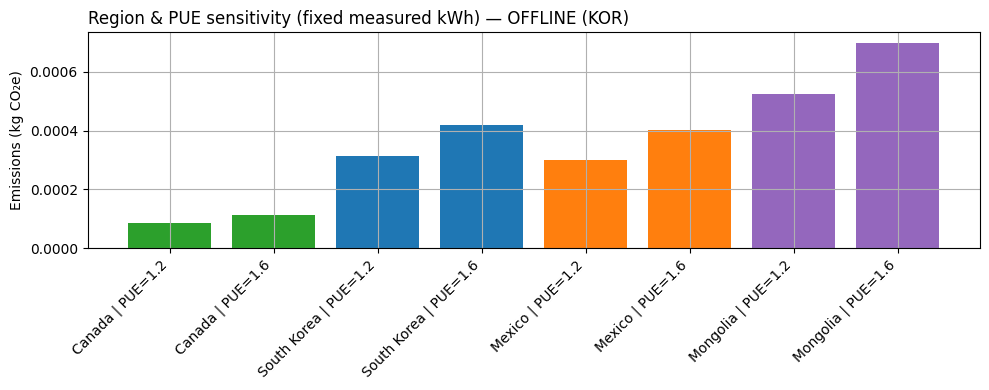

In [ ]:
# ============================================================
# Cell 8 — Region & PUE Sensitivity (fixed measured kWh)
# ============================================================

summary = json.loads((Path(RUN_DIR) / "summary.json").read_text())
measured_kwh = summary.get("total_energy_kwh")
baseline_pue = float(summary.get("pue", PUE))
mode_label   = (
    "ONLINE (auto)" if summary.get("tracker_mode") == "online"
    else f"OFFLINE ({summary.get('country_iso_code')})"
)

if measured_kwh is None:
    raise ValueError("total_energy_kwh missing in summary.json.")

measured_kwh = float(measured_kwh)

EMISSION_FACTORS = {
    "KOR": 0.45,
    "CAN": 0.12,
    "MEX": 0.43,
    "MNG": 0.75,
}
REGION_NAME = {
    "KOR": "South Korea",
    "CAN": "Canada",
    "MEX": "Mexico",
    "MNG": "Mongolia",
}
COUNTRY_COLOR = {
    "KOR": "#1f77b4",
    "CAN": "#2ca02c",
    "MEX": "#ff7f0e",
    "MNG": "#9467bd",
}

regions    = ["KOR", "CAN", "MEX", "MNG"]
pue_values = [round(baseline_pue, 2), 1.2, 1.6]

rows = []
for r in regions:
    ef = float(EMISSION_FACTORS[r])
    for p in pue_values:
        p = float(p)
        emissions_kg = measured_kwh * p * ef
        rows.append({
            "iso": r,
            "region": REGION_NAME[r],
            "pue": round(p, 2),
            "emissions_kg": emissions_kg,
        })

df_pue = pd.DataFrame(rows).sort_values(["iso", "pue"]).reset_index(drop=True)
display(df_pue)

fig = plt.figure(figsize=(10, 4), facecolor="white")
labels = [f"{row['region']} | PUE={row['pue']}" for _, row in df_pue.iterrows()]
colors = [COUNTRY_COLOR[row['iso']] for _, row in df_pue.iterrows()]
plt.bar(labels, df_pue["emissions_kg"], color=colors)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Emissions (kg CO₂e)")
plt.title(f"Region & PUE sensitivity (fixed measured kWh) — {mode_label}", loc="left", fontsize=12)
plt.tight_layout()
plt.show()


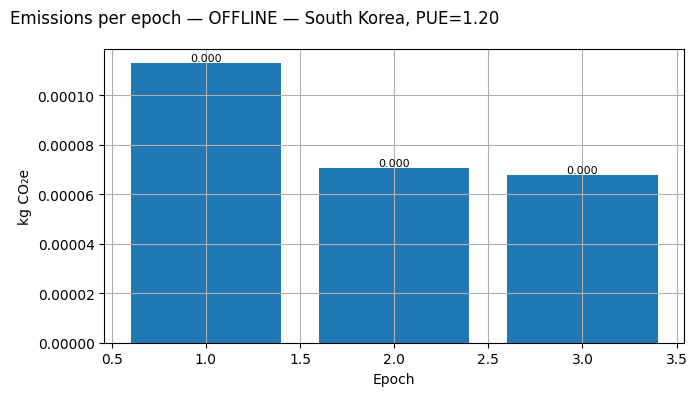

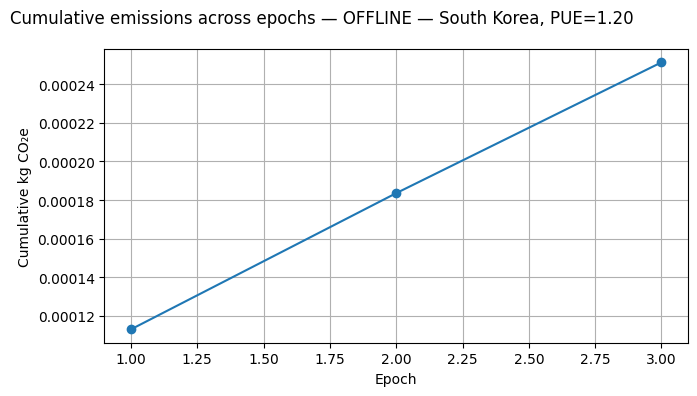

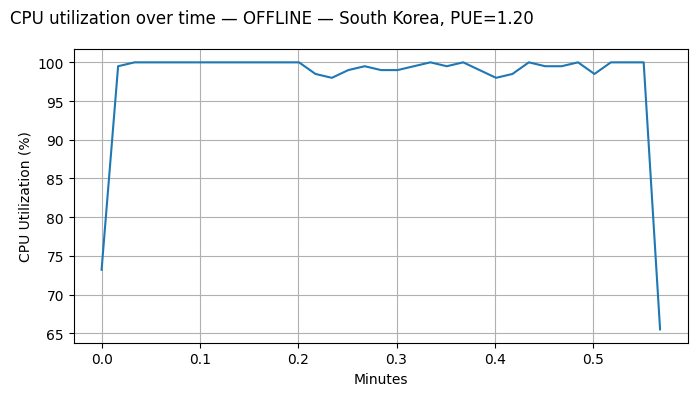

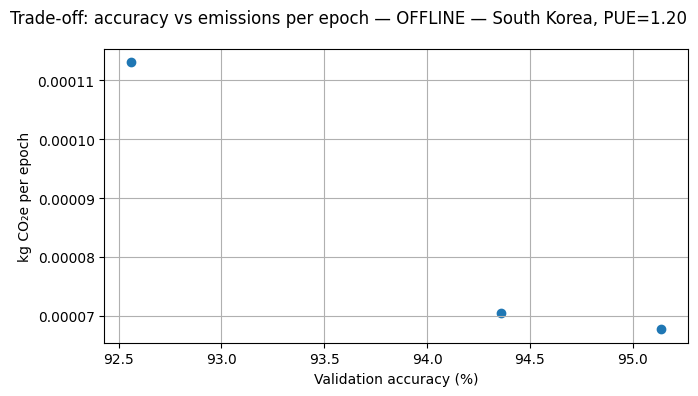

In [ ]:
# ============================================================
# Cell 9 — Dashboard Plots (Single Run)
# ============================================================

summary_path = Path(RUN_DIR) / "summary.json"
epochs_path  = Path(RUN_DIR) / "epochs.csv"
samples_path = Path(RUN_DIR) / "samples.csv"

summary    = json.loads(summary_path.read_text())
epochs_df  = pd.read_csv(epochs_path)
samples_df = pd.read_csv(samples_path)

iso        = summary.get("country_iso_code") or "online"
pue_val    = summary.get("pue", None)
mode       = summary.get("tracker_mode", "online")

REGION_NAME = {
    "KOR": "South Korea",
    "MEX": "Mexico",
    "CAN": "Canada",
    "MNG": "Mongolia",
}

region_label = REGION_NAME.get(iso, "Online (auto)" if iso == "online" else iso)

if pue_val is not None:
    try:
        pue_str = f", PUE={float(pue_val):.2f}"
    except Exception:
        pue_str = ""
else:
    pue_str = ""

context_tag = f"{'ONLINE' if mode == 'online' else 'OFFLINE'} — {region_label}{pue_str}"


def _title(s, fig):
    fig.suptitle(f"{s} — {context_tag}", x=0.01, y=0.98, ha="left", fontsize=12)


# 1) Emissions per epoch
fig = plt.figure(facecolor="white")
emissions_per_epoch = epochs_df["emissions_kg"].fillna(0.0)
plt.bar(epochs_df["epoch"], emissions_per_epoch)
plt.xlabel("Epoch")
plt.ylabel("kg CO₂e")

for i, v in enumerate(emissions_per_epoch):
    plt.text(
        epochs_df["epoch"].iloc[i],
        v,
        f"{v:.3f}",
        ha="center",
        va="bottom",
        fontsize=8,
    )

_title("Emissions per epoch", fig)
plt.tight_layout()
plt.show()

# 2) Cumulative emissions
fig = plt.figure(facecolor="white")
cum = emissions_per_epoch.cumsum()
plt.plot(epochs_df["epoch"], cum, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Cumulative kg CO₂e")
_title("Cumulative emissions across epochs", fig)
plt.tight_layout()
plt.show()

# 3) Utilization over time
fig = plt.figure(facecolor="white")
t0 = samples_df["timestamp"].iloc[0]
tmin = (samples_df["timestamp"] - t0) / 60.0

if "gpu_util_pct" in samples_df and samples_df["gpu_util_pct"].notna().any():
    plt.plot(tmin, samples_df["gpu_util_pct"].fillna(0.0))
    plt.ylabel("GPU Utilization (%)")
    _title("GPU utilization over time", fig)
else:
    plt.plot(tmin, samples_df["cpu_util_pct"].fillna(0.0))
    plt.ylabel("CPU Utilization (%)")
    _title("CPU utilization over time", fig)

plt.xlabel("Minutes")
plt.tight_layout()
plt.show()

# 4) Accuracy vs emissions
if "val_acc" in epochs_df and epochs_df["val_acc"].notna().any():
    fig = plt.figure(facecolor="white")
    plt.scatter(
        epochs_df["val_acc"] * 100.0,
        emissions_per_epoch,
    )
    plt.xlabel("Validation accuracy (%)")
    plt.ylabel("kg CO₂e per epoch")
    _title("Trade-off: accuracy vs emissions per epoch", fig)
    plt.tight_layout()
    plt.show()


In [ ]:
# ============================================================
# Cell 10 — Inspect All Runs in OUTPUT_ROOT
# ============================================================

%cd $OUTPUT_ROOT
!ls -lah


/content/carbon_logs
total 12K
drwxr-xr-x 3 root root 4.0K Nov 29 08:33 .
drwxr-xr-x 1 root root 4.0K Nov 29 08:33 ..
drwxr-xr-x 2 root root 4.0K Nov 29 08:34 20251129-083342_mnist_demo_KOR


=== Multi-Run Comparison (latest run per country) ===


,country_iso_code,run_dir,total_energy_kwh,total_emissions_kg,final_val_acc,kg_co2e_per_accuracy_pct
0,KOR,/content/carbon_logs/20251129-083342_mnist_dem...,0.000583,0.000251,0.9514,0.000003


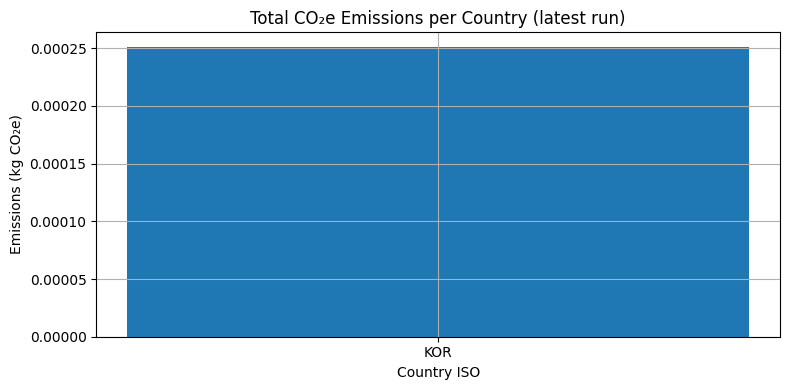

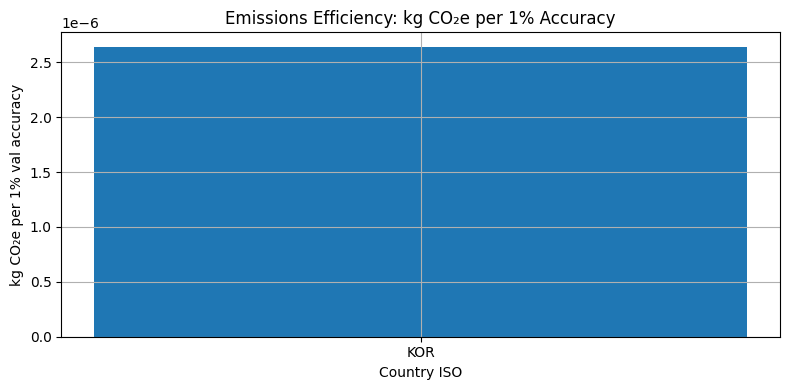

In [ ]:
# ============================================================
# Cell 11 — Multi-Run Comparison: CAN vs MEX vs KOR vs MNG
# ============================================================

ROOT = Path(OUTPUT_ROOT)
if not ROOT.exists():
    raise FileNotFoundError(f"OUTPUT_ROOT does not exist: {ROOT}")

target_countries = ["CAN", "MEX", "KOR", "MNG"]
latest_by_country = {}

for run_path in ROOT.iterdir():
    if not run_path.is_dir():
        continue
    summary_path = run_path / "summary.json"
    if not summary_path.exists():
        continue
    try:
        summary = json.loads(summary_path.read_text())
    except Exception:
        continue

    iso = summary.get("country_iso_code")
    if iso not in target_countries:
        continue

    mtime = run_path.stat().st_mtime
    if iso not in latest_by_country or mtime > latest_by_country[iso][2]:
        latest_by_country[iso] = (run_path, summary, mtime)

if not latest_by_country:
    raise RuntimeError(
        "No runs found for CAN/MEX/KOR/MNG. "
        "Please run Cell 2 & 6 four times with COUNTRY_ISO_CODE='CAN','MEX','KOR','MNG'."
    )

rows = []
for iso, (run_path, summary, _) in latest_by_country.items():
    epochs_path = run_path / "epochs.csv"
    final_acc = None
    if epochs_path.exists():
        df_ep = pd.read_csv(epochs_path)
        if "val_acc" in df_ep.columns and df_ep["val_acc"].notna().any():
            final_acc = float(df_ep["val_acc"].dropna().tail(1).values[0])

    total_kg  = summary.get("total_emissions_kg")
    total_kwh = summary.get("total_energy_kwh")

    if total_kg is not None and final_acc is not None and final_acc > 0:
        kg_per_pct = total_kg / (final_acc * 100.0)
    else:
        kg_per_pct = None

    rows.append({
        "country_iso_code": iso,
        "run_dir": str(run_path),
        "total_energy_kwh": total_kwh,
        "total_emissions_kg": total_kg,
        "final_val_acc": final_acc,
        "kg_co2e_per_accuracy_pct": kg_per_pct,
    })

comp_df = pd.DataFrame(rows).sort_values("country_iso_code").reset_index(drop=True)

print("=== Multi-Run Comparison (latest run per country) ===")
display(comp_df)

plt.figure(figsize=(8, 4))
plt.bar(comp_df["country_iso_code"], comp_df["total_emissions_kg"])
plt.title("Total CO₂e Emissions per Country (latest run)")
plt.xlabel("Country ISO")
plt.ylabel("Emissions (kg CO₂e)")
plt.tight_layout()
plt.show()

if comp_df["kg_co2e_per_accuracy_pct"].notna().any():
    plt.figure(figsize=(8, 4))
    plt.bar(
        comp_df["country_iso_code"],
        comp_df["kg_co2e_per_accuracy_pct"].fillna(0.0),
    )
    plt.title("Emissions Efficiency: kg CO₂e per 1% Accuracy")
    plt.xlabel("Country ISO")
    plt.ylabel("kg CO₂e per 1% val accuracy")
    plt.tight_layout()
    plt.show()


In [ ]:
# ============================================================
# Cell 12 — OPTIONAL: Zip Latest ONLINE & OFFLINE-KOR Runs
# ============================================================

from pathlib import Path

ROOT = Path(OUTPUT_ROOT)

def load_summary(run_dir: Path):
    sj = run_dir / "summary.json"
    if not sj.exists():
        return None
    try:
        return json.loads(sj.read_text())
    except Exception:
        return None

def find_latest(root: Path, *, mode=None, country=None):
    candidates = []
    for p in root.iterdir():
        if not p.is_dir():
            continue
        s = load_summary(p)
        if not s:
            continue
        if mode and s.get("tracker_mode") != mode:
            continue
        if country is not None and s.get("country_iso_code") != country:
            continue
        candidates.append(p)
    if not candidates:
        return None
    return max(candidates, key=lambda q: q.stat().st_mtime)

def zip_run(run_dir: Path, out_zip: Path):
    print(f"Zipping → {out_zip} (from {run_dir})")
    get_ipython().system(f'zip -r "{out_zip}" "{run_dir}"')
    get_ipython().system(f'unzip -l "{out_zip}" | head -n 20')

online_latest = find_latest(ROOT, mode="online")
kor_latest    = find_latest(ROOT, mode="offline", country="KOR")

if online_latest:
    online_zip = Path("/content/mnist_demo_online_carbonmeter.zip")
    zip_run(online_latest, online_zip)
else:
    print("No ONLINE run found (tracker_mode='online').")

if kor_latest:
    kor_zip = Path("/content/mnist_demo_kor_carbonmeter.zip")
    zip_run(kor_latest, kor_zip)
else:
    print("No OFFLINE-KOR run found.")

print("Done.")


No ONLINE run found (tracker_mode='online').
Zipping → /content/mnist_demo_kor_carbonmeter.zip (from /content/carbon_logs/20251129-083342_mnist_demo_KOR)
  adding: content/carbon_logs/20251129-083342_mnist_demo_KOR/ (stored 0%)
  adding: content/carbon_logs/20251129-083342_mnist_demo_KOR/summary.json (deflated 49%)
  adding: content/carbon_logs/20251129-083342_mnist_demo_KOR/samples.csv (deflated 73%)
  adding: content/carbon_logs/20251129-083342_mnist_demo_KOR/epochs.csv (deflated 42%)
  adding: content/carbon_logs/20251129-083342_mnist_demo_KOR/emissions.csv (deflated 38%)
Archive:  /content/mnist_demo_kor_carbonmeter.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
        0  2025-11-29 08:34   content/carbon_logs/20251129-083342_mnist_demo_KOR/
     1068  2025-11-29 08:34   content/carbon_logs/20251129-083342_mnist_demo_KOR/summary.json
     2545  2025-11-29 08:34   content/carbon_logs/20251129-083342_mnist_demo_KOR/samples.csv
      472  2025-11-29 08:34  

In [ ]:
!zip -r /content/run_bundle_kor.zip "/content/carbon_logs/20251125-050922_mnist_demo_KOR"


	zip warning: name not matched: /content/carbon_logs/20251125-050922_mnist_demo_KOR

zip error: Nothing to do! (try: zip -r /content/run_bundle_kor.zip . -i /content/carbon_logs/20251125-050922_mnist_demo_KOR)
